# Taller 2 – Funciones kernel en la clasificación de zonas de irradiancia

**Objetivo.** Comparar un conjunto de funciones kernel (Belanche) en la clasificación de irradiancia a partir de imágenes
multiespectrales (**Landsat** y **MODIS**), usando distintos *pipelines* y evaluándolos de forma justa. Los mejores
pipelines se exportan a una aplicación web (carpeta `webapp/`).

**Contenido**

| Punto | Sección |
|---|---|
| 1. Datasets Landsat y MODIS | §1 |
| 2. Clases `KSVC` y `KANN`, y `KRidgeClassifier` (RidgeClassifier + truco kernel) | §2 |
| 3. Pipelines: Escalador × Discretizador × Reductor × Modelo | §3 y §4 |
| 4. Evaluación justa: Accuracy, F1, AUC, MCC, matrices de confusión y curvas PR | §5 – §6 |
| Conclusiones | §7 |
| Exportación de los mejores pipelines a la app | §8 |

**Decisiones de diseño** (acordadas con el enunciado y con quien lo desarrolla):

* Landsat y MODIS se tratan como **dos conjuntos independientes** (tienen escalas de bandas muy distintas).
* Se discretiza la irradiancia en **3 clases ordenadas** (0 = baja, 1 = media, 2 = alta).
* Los *features* son **solo las 7 bandas** (sin coordenadas) para que el modelo no memorice posiciones; en la app se usan
  las bandas del punto de datos más cercano al sitio donde se pica.
* `KRidgeClassifier` entra como **tercer modelo** del pipeline junto a `KSVC` y `KANN`.
* Búsqueda de hiperparámetros con `RandomizedSearchCV` reducido (20 candidatos, validación cruzada de 3 pliegues).

In [1]:
import sys, os, time, json, warnings, itertools
sys.path.insert(0, os.getcwd())          # el notebook se ejecuta desde la carpeta Taller2
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, uniform
from joblib import Parallel, delayed
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import precision_recall_curve, average_precision_score, ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize
from sklearn.base import clone

from kernelml import KSVC, KANNC, KRidgeClassifier, TargetDiscretizer, evaluate_classifier, class_scores
from kernelml.KernelUtilities import PAIRWISE, pairwise_gram, gram_matrix, KERNEL_NAMES
from kernelml.discretizers import METHODS

SEED = 2025
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLASS_NAMES = ["baja", "media", "alta"]
CLASS_COLORS = ["#2b83ba", "#fdae61", "#d7191c"]

## 1. Datasets Landsat y MODIS (punto 1)

Cada fila es un píxel de la región de Nariño: coordenadas, 7 bandas espectrales (`band1`…`band7`) y la irradiancia
medida/estimada (`value`), que es la variable objetivo.

> **Nota sobre las coordenadas.** Las columnas se llaman `latitude`/`longitude`, pero sus valores (≈ −8.7·10⁶ y ≈ 1.7·10⁵)
> son metros en **EPSG:3857 (Web Mercator)** y están *intercambiadas*: `latitude` es en realidad el eje X (este-oeste) y
> `longitude` el eje Y (norte-sur). Se convierten a grados WGS84 con `pyproj` solo para visualización/aplicación web.

In [2]:
DATASETS = {"landsat": "landsat_model.csv", "modis": "modis_model.csv"}
BANDS = [f"band{i}" for i in range(1, 8)]
data = {k: pd.read_csv(f) for k, f in DATASETS.items()}
for k, d in data.items():
    print(f"== {k}: {d.shape[0]} filas, nulos: {int(d.isna().sum().sum())}")
display(pd.concat({k: d[BANDS + ['value']].describe().T[['min', 'mean', 'max']] for k, d in data.items()}, axis=1).round(3))

== landsat: 434 filas, nulos: 0
== modis: 445 filas, nulos: 0


landsat                       modis                    
           min     mean      max       min      mean       max
band1    0.063    0.095    0.121  1934.563  3278.960  4402.589
band2    0.047    0.080    0.102  3161.654  4504.219  5296.896
band3    0.031    0.054    0.079  1897.326  3383.796  4513.473
band4    0.156    0.289    0.410  2024.835  3415.465  4525.708
band5    0.054    0.135    0.263  3086.360  4397.343  5039.512
band6  286.149  295.471  302.222  2409.229  3207.855  3700.447
band7    0.018    0.051    0.118  1582.516  1970.024  2374.839
value  188.500  209.868  247.300   188.500   210.182   248.100

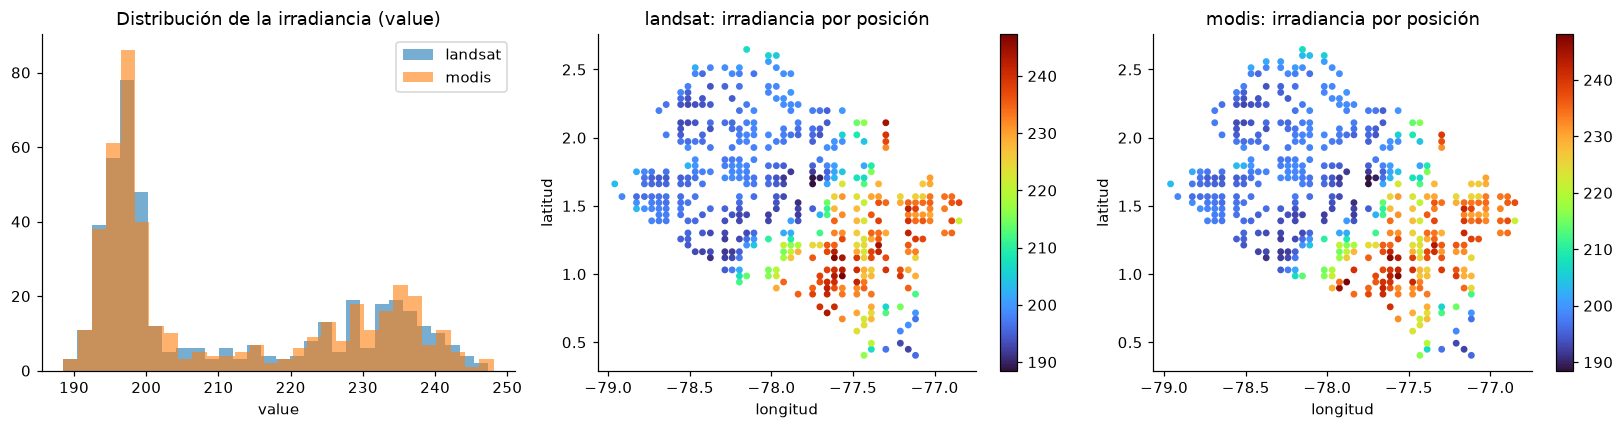

     lon_deg  lat_deg
min  -78.961    0.404
max  -76.850    2.647


In [3]:
from pyproj import Transformer
tr = Transformer.from_crs(3857, 4326, always_xy=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, d in data.items():
    lon, lat = tr.transform(d["latitude"].values, d["longitude"].values)   # (X, Y) -> (lon, lat)
    d["lon_deg"], d["lat_deg"] = lon, lat
    ax[0].hist(d["value"], bins=30, alpha=.6, label=k)
ax[0].set(title="Distribución de la irradiancia (value)", xlabel="value"); ax[0].legend()
for a, (k, d) in zip(ax[1:], data.items()):
    s = a.scatter(d["lon_deg"], d["lat_deg"], c=d["value"], s=12, cmap="turbo")
    a.set(title=f"{k}: irradiancia por posición", xlabel="longitud", ylabel="latitud"); plt.colorbar(s, ax=a)
plt.tight_layout(); plt.show()
print(data["landsat"][["lon_deg", "lat_deg"]].describe().loc[["min", "max"]].round(3))

La irradiancia es **bimodal** (un grupo grande en ≈ 190–200 y otro en ≈ 225–245): esto anticipa que las clases no serán
balanceadas, lo que condiciona la elección de métricas y de la curva (§6.2).

## 2. Funciones kernel, `KSVC`, `KANN` y `KRidgeClassifier` (punto 2)

### 2.1 Funciones kernel
El repositorio usa `KernelUtilities` (funciones de Belanche) que está incrustado en `Regressor.ipynb`; se extrajo a
`kernelml/KernelUtilities.py`. Los kernels comparados son los del artículo de referencia:

| nombre | kernel | parámetros |
|---|---|---|
| `rbf` | RBF `exp(−γ‖x−y‖²)` | γ |
| `rquadratic` | cuadrático racional `1 − ‖x−y‖²/(‖x−y‖²+c)` | c (`coef0`) |
| `tru` | truncado | γ |
| `can` | Canberra | γ |
| `radial_basic` | ANOVA `(Σ exp(−γ(xᵢ−yᵢ)²))^m` | γ, m (`degree`) |
| `triangle` | triangular `1 − ‖x−y‖/γ` si `‖x−y‖≤γ` | γ |
| `hyperbolic` | tangente hiperbólica `tanh(γ x·y + c)` | γ, c |

**Mejoras de ingeniería respecto al código original** (la matemática no cambia):
1. El original calcula la matriz de Gram con dos bucles de Python (muy lento). Se **vectorizó** con numpy.
2. Los kernels eran *closures* (no se pueden serializar con `pickle`). Ahora son objetos de clase, imprescindible para
   **almacenar los modelos** en la app web.
3. En `KANN` el original ignoraba `gamma`/`coef0` en `hyperbolic` y `coef0` en `rquadratic`, y `predict_proba` no
   transformaba los datos. Se corrigió.
4. `KSVC.fit` devolvía `None` si el kernel ya era un callable (p. ej. al clonar o reajustar). Se corrigió.

Se **verifica** que la versión vectorizada reproduce exactamente las funciones originales par a par:

In [4]:
rng = np.random.RandomState(0)
A, B = rng.rand(15, 7) + .1, rng.rand(9, 7) + .1
chk = {k: np.abs(pairwise_gram(k, A, B, 2, .7, .3) - gram_matrix(k, A, B, 2, .7, .3)).max() for k in KERNEL_NAMES}
print("máxima diferencia |K_original − K_vectorizada|:")
display(pd.Series(chk).to_frame("max_abs_diff"))
t0 = time.time(); pairwise_gram("rbf", np.tile(A, (20, 1)), np.tile(A, (20, 1)), 2, .7, .3); t_loop = time.time() - t0
t0 = time.time(); gram_matrix("rbf", np.tile(A, (20, 1)), np.tile(A, (20, 1)), 2, .7, .3); t_vec = time.time() - t0
print(f"Gram 300x300: bucle original {t_loop:.3f}s vs vectorizada {t_vec:.4f}s  (x{t_loop/t_vec:.0f})")

máxima diferencia |K_original − K_vectorizada|:


,max_abs_diff
poly,7.105427e-15
rbf,0.000000e+00
hyperbolic,1.110223e-16
triangle,0.000000e+00
radial_basic,7.105427e-15
rquadratic,2.220446e-16
can,0.000000e+00
tru,0.000000e+00


Gram 300x300: bucle original 0.679s vs vectorizada 0.0110s  (x62)


### 2.2 `KSVC` y `KANN` (del repositorio)
* **`KSVC`** extiende `sklearn.svm.SVC`: el parámetro `kernel` acepta, además de `linear/poly/rbf`, los kernels de Belanche
  que se pasan a `SVC` como función de Gram.
* **`KANNC`** extiende `MLPClassifier`: aproxima el kernel con **Nyström** (100 componentes) y entrena un perceptrón
  multicapa sobre ese mapa de características (activación identidad por defecto).

### 2.3 `KRidgeClassifier` = `RidgeClassifier` + truco kernel
`RidgeClassifier` codifica las clases como {−1, +1} (uno-contra-todos) y resuelve una regresión ridge
$\min_w \|Y - Xw\|^2 + \alpha\|w\|^2$. Su solución en forma **dual** es $w = X^\top a$ con
$a = (XX^\top + \alpha I)^{-1}Y$, de modo que los datos solo intervienen mediante productos punto $XX^\top$.
Reemplazándolos por una matriz de Gram $K(X,X)$ de cualquier kernel (**truco kernel**):

$$a = (K+\alpha I)^{-1}(Y-\bar Y), \qquad f(x) = K(x, X_{train})\,a + \bar Y, \qquad \hat y = \arg\max_k f_k(x)$$

Se implementó en `kernelml/KRidge.py` heredando de `RidgeClassifier` (mismo API: `fit/predict/decision_function`, `alpha`,
`class_weight`) y añadiendo `kernel, degree, gamma, coef0`. Como algunos kernels no son definidos positivos
(p. ej. `hyperbolic`), si el sistema falla se resuelve por mínimos cuadrados.

**Validación**: con kernel RBF debe coincidir exactamente con `KernelRidge` de sklearn sobre los objetivos {−1,+1} centrados:

In [5]:
from sklearn.kernel_ridge import KernelRidge
d = data["landsat"]; X_ = StandardScaler().fit_transform(d[BANDS].values)
y_ = TargetDiscretizer("kmeans").fit_transform(d["value"].values)
kr = KRidgeClassifier(alpha=0.5, kernel="rbf", gamma=0.2).fit(X_, y_)
Y_ = 2 * label_binarize(y_, classes=[0, 1, 2]) - 1.0
ref = KernelRidge(alpha=0.5, kernel="rbf", gamma=0.2).fit(X_, Y_ - Y_.mean(0))
print("max |KRidgeClassifier - KernelRidge| =", np.abs(kr.decision_function(X_) - (ref.predict(X_) + Y_.mean(0))).max())
print("accuracy en entrenamiento:", (kr.predict(X_) == y_).mean())

max |KRidgeClassifier - KernelRidge| = 1.4210854715202004e-14
accuracy en entrenamiento: 0.9078341013824884


## 3. Espacio de pipelines (punto 3)

Siguiendo el artículo de referencia y `Regressor.ipynb`, un pipeline es la composición

**Discretizador de y → Escalador → Reductor de dimensionalidad → Modelo(kernel)**

| Etapa | Opciones |
|---|---|
| Escalador | `StandardScaler`, `MinMaxScaler`, `Normalizer` |
| Discretizador de la variable objetivo (3 clases) | `uniform` (rangos de igual ancho), `kmeans`, `hierarchical` (aglomerativo Ward), `dbscan` |
| Reductor | `PCA` (nº de componentes ∈ {2, 3, 5}), `LDA` (supervisado, 2 componentes = clases−1) |
| Modelo | `KSVC`, `KANN`, `KRidge` |
| Kernel (hiperparámetro) | `rbf, rquadratic, tru, can, radial_basic, triangle, hyperbolic` |

Total: 3 × 4 × 2 × 3 = **72 pipelines por dataset**, cada uno con 7 kernels = 504 configuraciones por dataset
(1008 en total), todas con su propia búsqueda de hiperparámetros.

### 3.1 Discretizadores
* El discretizador se **ajusta solo con el y de entrenamiento** y luego clasifica cualquier valor nuevo
  (test o puntos del mapa) → sin fuga de información.
* Los métodos de clustering ordenan los clusters de menor a mayor irradiancia media. Los valores nuevos se asignan al
  cluster del vecino más cercano.
* **DBSCAN** no permite fijar el número de clases: se busca `eps` (con `min_samples` = 5 % de n) que produzca un número
  de clusters lo más cercano posible a 3; el ruido se reasigna al cluster más cercano.

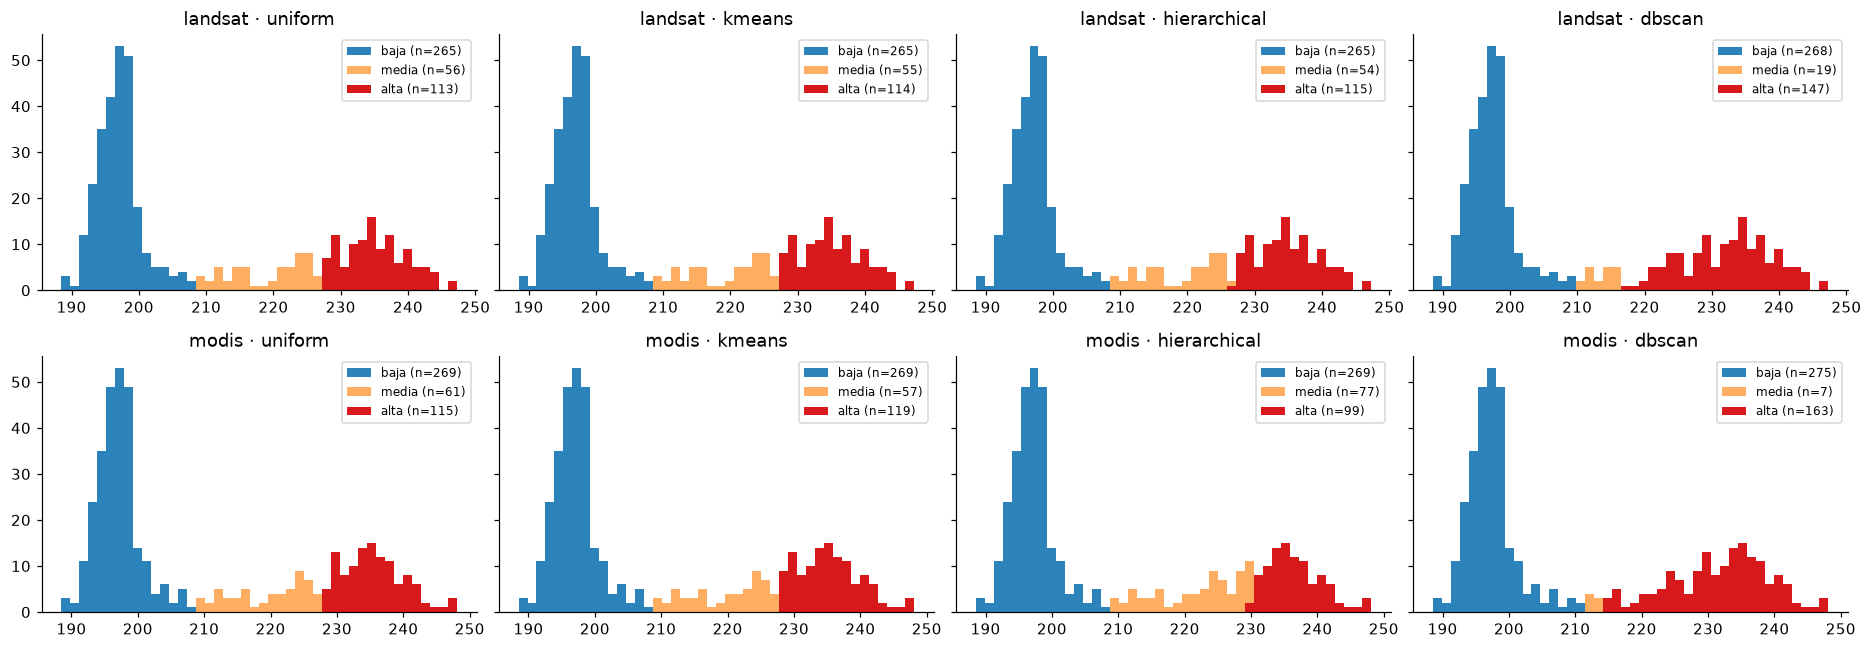

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6), sharey="row")
for r, (k, d) in enumerate(data.items()):
    y = d["value"].values
    for c, m in enumerate(METHODS):
        disc = TargetDiscretizer(m, 3, random_state=0).fit(y); lab = disc.transform(y)
        for cl in range(disc.n_classes_):
            axes[r, c].hist(y[lab == cl], bins=np.linspace(y.min(), y.max(), 45), color=CLASS_COLORS[cl], label=f"{CLASS_NAMES[cl]} (n={disc.counts_[cl]})")
        axes[r, c].set_title(f"{k} · {m}"); axes[r, c].legend(fontsize=8)
plt.tight_layout(); plt.show()

Se observa que `uniform`, `kmeans` y `hierarchical` producen cortes casi idénticos (la distribución es bimodal) y que
`DBSCAN` aísla una clase intermedia más pequeña. En todos los casos la clase **baja es mayoritaria (~60 %)**: hay
**desbalance de clases**.

### 3.2 Protocolo de evaluación justa
1. **Un único split estratificado 80/20** (misma semilla, mismas filas) para todos los pipelines de un dataset; la
   estratificación usa cuantiles de `value` (independientes del discretizador).
2. El **discretizador, el escalador, el reductor y el modelo se ajustan únicamente con el conjunto de entrenamiento.**
3. Los **hiperparámetros se eligen por validación cruzada estratificada (3 pliegues) solo sobre entrenamiento**, optimizando
   F1-macro (robusto al desbalance). El conjunto de prueba se usa **una sola vez** por configuración.
4. Todos los modelos reciben el **mismo presupuesto de búsqueda** (20 candidatos aleatorios con las mismas distribuciones
   de γ, C, α…) y la misma semilla.
5. Métricas en test: **Accuracy, F1-macro, AUC (OvR macro), MCC** + matriz de confusión.
6. La **selección de los mejores pipelines se hace con el F1-macro de validación cruzada** (no con el test), de modo que
   las métricas de test de los elegidos son una estimación no sesgada por la selección.

> **Limitación**: con ~430 píxeles, el test tiene solo ≈ 87 filas; por eso para los finalistas se añade una evaluación
> repetida (§6.3) que da la variabilidad de las métricas.

In [7]:
# ---- split estratificado, idéntico para todos los pipelines de cada dataset ----
SPLITS = {}
for k, d in data.items():
    strat = pd.qcut(d["value"], 5, labels=False, duplicates="drop")
    idx_tr, idx_te = train_test_split(np.arange(len(d)), test_size=0.2, random_state=SEED, stratify=strat)
    SPLITS[k] = (idx_tr, idx_te)
    print(k, "train:", len(idx_tr), "test:", len(idx_te))

landsat train: 347 test: 87
modis train: 356 test: 89


## 4. Búsqueda de hiperparámetros en todos los pipelines (punto 3)

Se definen los componentes y los **espacios de búsqueda** (distribuciones log-uniformes para γ, C, α y coef0).
Cada configuración `(dataset, discretizador, escalador, reductor, modelo, kernel)` se evalúa en paralelo.

In [8]:
SCALERS = {"StandardScaler": StandardScaler, "MinMaxScaler": MinMaxScaler, "Normalizer": Normalizer}
REDUCERS = ["PCA", "LDA"]
MODELS = ["KSVC", "KANN", "KRidge"]
KERNELS = ["rbf", "rquadratic", "tru", "can", "radial_basic", "triangle", "hyperbolic"]
N_ITER, CV_FOLDS = 20, 3

def build_pipeline(scaler, reducer, model, kernel=None):
    red = PCA(random_state=0) if reducer == "PCA" else LinearDiscriminantAnalysis()
    mdl = {"KSVC": KSVC(), "KANN": KANNC(max_iter=300, random_state=0), "KRidge": KRidgeClassifier()}[model]
    return Pipeline([("scaler", SCALERS[scaler]()), ("reducer", red), ("model", mdl)])

def param_space(model, kernel, reducer):
    # mismos rangos para todos los modelos => presupuesto de búsqueda comparable
    p = {"model__kernel": [kernel]}
    if kernel != "rquadratic":
        p["model__gamma"] = loguniform(1e-3, 1e3)        # en rquadratic gamma no interviene
    if kernel == "rquadratic":
        p["model__coef0"] = loguniform(1e-3, 1e3)
    if kernel == "hyperbolic":
        p["model__coef0"] = uniform(-5, 5)               # Belanche: b < 0
    if kernel == "radial_basic":
        p["model__degree"] = [1, 2, 3, 4]
    if model == "KSVC":
        p["model__C"] = loguniform(1e-1, 1e4)
    elif model == "KANN":
        p["model__alpha"] = loguniform(1e-5, 1e-1)
        p["model__hidden_layer_sizes"] = [(50,), (100,)]
    elif model == "KRidge":
        p["model__alpha"] = loguniform(1e-4, 1e2)
    if reducer == "PCA":
        p["reducer__n_components"] = [2, 3, 5]
    return p

def run_config(cfg):
    # una configuración: ajusta discretizador, busca hiperparámetros por CV (solo train) y evalúa en test
    import warnings; warnings.filterwarnings("ignore")
    ds, disc_m, scaler, reducer, model, kernel = cfg
    d = data[ds]; idx_tr, idx_te = SPLITS[ds]
    X, y = d[BANDS].values, d["value"].values
    base = dict(dataset=ds, discretizer=disc_m, scaler=scaler, reducer=reducer, model=model, kernel=kernel)
    try:
        disc = TargetDiscretizer(disc_m, 3, random_state=0).fit(y[idx_tr])
        ytr, yte = disc.transform(y[idx_tr]), disc.transform(y[idx_te])
        t0 = time.time()
        search = RandomizedSearchCV(build_pipeline(scaler, reducer, model), param_space(model, kernel, reducer),
                                    n_iter=N_ITER, scoring="f1_macro", error_score=0.0,
                                    cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED),
                                    random_state=SEED, n_jobs=1, refit=True)
        search.fit(X[idx_tr], ytr)
        fit_time = time.time() - t0
        best = search.best_estimator_
        m = evaluate_classifier(best, X[idx_te], yte, list(disc.classes_))
        i = search.best_index_
        params = {k_.replace("model__", "").replace("reducer__", "red_"): (v if not isinstance(v, (np.floating, np.integer)) else v.item())
                  for k_, v in search.best_params_.items()}
        return {**base, "cv_f1": search.best_score_, "cv_f1_std": search.cv_results_["std_test_score"][i],
                "n_classes": disc.n_classes_, "class_counts_train": disc.counts_,
                **{k_: m[k_] for k_ in ["accuracy", "f1_macro", "auc_ovr", "mcc"]},
                "confusion_matrix": m["confusion_matrix"], "fit_time_s": fit_time, "params": params, "error": ""}
    except Exception as e:
        return {**base, "error": repr(e)[:200]}

configs = list(itertools.product(DATASETS, METHODS, SCALERS, REDUCERS, MODELS, KERNELS))
print("configuraciones:", len(configs))

configuraciones: 1008


In [9]:
os.makedirs("results", exist_ok=True)
RESULTS_CSV = "results/results_all.csv"
if os.path.exists(RESULTS_CSV):                       # cache: evita repetir ~horas de cómputo
    res = pd.read_csv(RESULTS_CSV)
    print("cargado desde cache:", RESULTS_CSV, res.shape)
else:
    t0 = time.time()
    out = Parallel(n_jobs=-1, verbose=3)(delayed(run_config)(c) for c in configs)
    res = pd.DataFrame(out)
    res["confusion_matrix"] = res["confusion_matrix"].apply(json.dumps)
    res["params"] = res["params"].apply(json.dumps)
    res.to_csv(RESULTS_CSV, index=False)
    print(f"listo en {(time.time()-t0)/60:.1f} min -> {RESULTS_CSV}")
print("errores:", int((res["error"].fillna("") != "").sum()), "de", len(res))
res["params"] = res["params"].apply(lambda s: json.loads(s) if isinstance(s, str) else s)
res["confusion_matrix"] = res["confusion_matrix"].apply(lambda s: json.loads(s) if isinstance(s, str) else s)
res["pipeline"] = res["scaler"].str.replace("Scaler", "") + " | " + res["discretizer"] + " | " + res["reducer"] + " | " + res["model"] + "-" + res["kernel"]
res.head(3)

cargado desde cache: results/results_all.csv (1008, 18)
errores: 0 de 1008


,dataset,discretizer,scaler,reducer,model,kernel,cv_f1,cv_f1_std,n_classes,class_counts_train,accuracy,f1_macro,auc_ovr,mcc,confusion_matrix,fit_time_s,params,error,pipeline
0,landsat,uniform,StandardScaler,PCA,KSVC,rbf,0.732299,0.059263,3,"[213, 44, 90]",0.839080,0.684521,0.885028,0.705053,"[[51, 1, 0], [2, 3, 7], [1, 3, 19]]",1.988403,"{'C': 43.902846639816396, 'gamma': 0.151094325...",NaN,Standard | uniform | PCA | KSVC-rbf
1,landsat,uniform,StandardScaler,PCA,KSVC,rquadratic,0.749700,0.034076,3,"[213, 44, 90]",0.850575,0.673661,0.928025,0.737459,"[[50, 2, 0], [1, 2, 9], [0, 1, 22]]",1.659322,"{'C': 1.9408062250533484, 'coef0': 8.794385781...",NaN,Standard | uniform | PCA | KSVC-rquadratic
2,landsat,uniform,StandardScaler,PCA,KSVC,tru,0.749323,0.056307,3,"[213, 44, 90]",0.793103,0.622656,0.885510,0.628101,"[[49, 3, 0], [2, 2, 8], [0, 5, 18]]",2.429579,"{'C': 2.9110318708252225, 'gamma': 4.628987371...",NaN,Standard | uniform | PCA | KSVC-tru


## 5. Resultados: comparación de kernels, escaladores, reductores y modelos (punto 4)

Todas las cifras son métricas sobre el **conjunto de prueba** (excepto `cv_f1`, que es validación cruzada sobre train).

In [10]:
METRICS = ["accuracy", "f1_macro", "auc_ovr", "mcc"]
ok = res[res["error"].fillna("") == ""].copy()
print("Resumen global (media de las 504 configuraciones por dataset):")
display(ok.groupby("dataset")[METRICS + ["cv_f1", "fit_time_s"]].agg(["mean", "max"]).round(3))

Resumen global (media de las 504 configuraciones por dataset):


accuracy        f1_macro        auc_ovr           mcc         cv_f1  \
            mean    max     mean    max    mean    max   mean    max   mean   
dataset                                                                       
landsat    0.797  0.897    0.644  0.839   0.882  0.967  0.612  0.814  0.661   
modis      0.811  0.966    0.623  0.869   0.857  0.996  0.641  0.932  0.671   

               fit_time_s          
           max       mean     max  
dataset                            
landsat  0.840      4.189  16.750  
modis    0.845      4.178  21.338

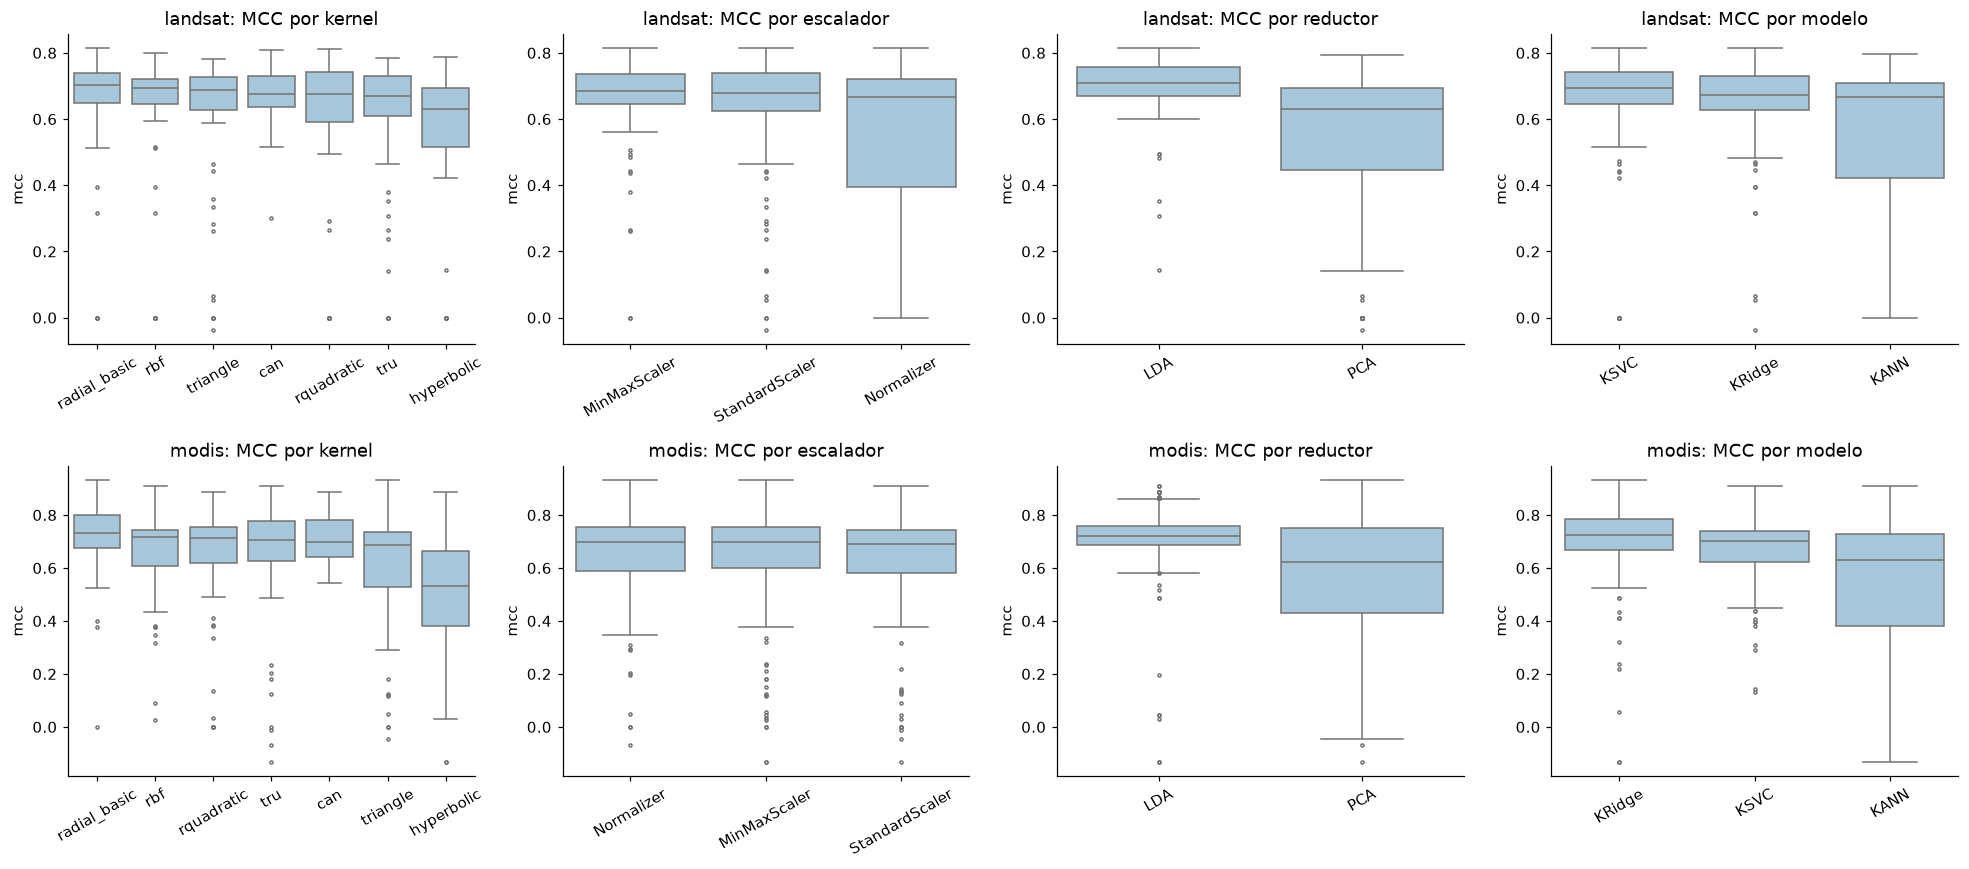

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for r, ds in enumerate(DATASETS):
    sub = ok[ok.dataset == ds]
    for c, (col, title) in enumerate([("kernel", "kernel"), ("scaler", "escalador"), ("reducer", "reductor"), ("model", "modelo")]):
        order = sub.groupby(col)["mcc"].median().sort_values(ascending=False).index
        sns.boxplot(data=sub, x=col, y="mcc", order=order, ax=axes[r, c], color="#9ecae1", fliersize=2)
        axes[r, c].set_title(f"{ds}: MCC por {title}"); axes[r, c].tick_params(axis="x", rotation=30); axes[r, c].set_xlabel("")
plt.tight_layout(); plt.show()

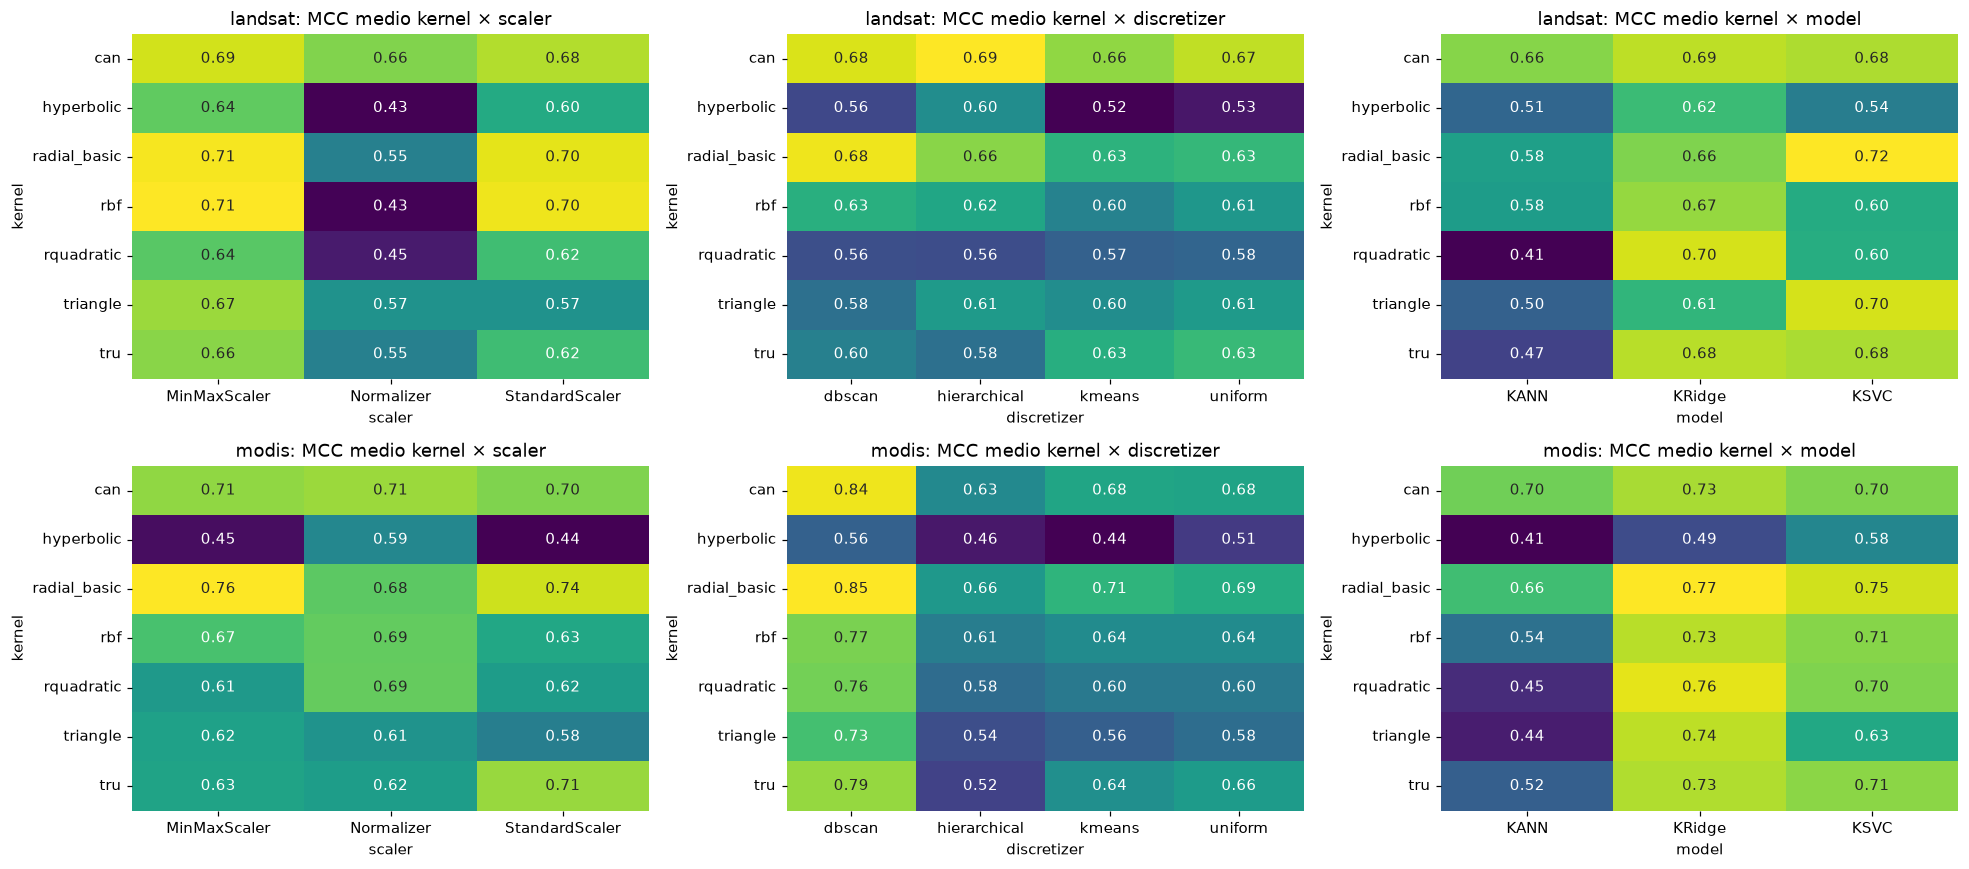

In [12]:
# Mapas de calor: MCC medio (test) de cada kernel frente al resto de factores
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for r, ds in enumerate(DATASETS):
    sub = ok[ok.dataset == ds]
    for c, other in enumerate(["scaler", "discretizer", "model"]):
        sns.heatmap(sub.pivot_table(index="kernel", columns=other, values="mcc", aggfunc="mean"), annot=True, fmt=".2f",
                    cmap="viridis", ax=axes[r, c], cbar=False)
        axes[r, c].set_title(f"{ds}: MCC medio kernel × {other}")
plt.tight_layout(); plt.show()

### 5.1 Ranking y tiempos
**Importante:** el ranking de pipelines se hace con `cv_f1` (validación cruzada sobre entrenamiento, no con el test).
Comparar métricas **entre discretizadores** debe hacerse con cautela, porque cada discretizador define un problema distinto
(clases y balance distintos); dentro de cada discretizador la comparación es directa.

In [13]:
cols = ["pipeline", "cv_f1", "accuracy", "f1_macro", "auc_ovr", "mcc", "fit_time_s"]
for ds in DATASETS:
    print(f"\n===== {ds}: top 10 por cv_f1 (validación cruzada en train) =====")
    display(ok[ok.dataset == ds].sort_values("cv_f1", ascending=False).head(10)[cols].round(3).reset_index(drop=True))


===== landsat: top 10 por cv_f1 (validación cruzada en train) =====


,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc,fit_time_s
0,MinMax | dbscan | PCA | KSVC-radial_basic,0.840,0.862,0.768,0.860,0.750,3.678
1,Standard | dbscan | PCA | KSVC-radial_basic,0.840,0.874,0.778,0.860,0.768,3.133
2,MinMax | hierarchical | PCA | KSVC-radial_basic,0.808,0.851,0.782,0.870,0.739,2.925
3,Normalizer | kmeans | LDA | KSVC-rquadratic,0.808,0.816,0.683,0.857,0.669,1.511
4,Standard | kmeans | LDA | KRidge-can,0.805,0.805,0.602,0.912,0.646,2.412
5,MinMax | kmeans | LDA | KRidge-can,0.805,0.805,0.602,0.912,0.646,3.353
6,Standard | kmeans | LDA | KSVC-can,0.804,0.828,0.618,0.839,0.686,1.989
7,MinMax | kmeans | LDA | KSVC-can,0.804,0.828,0.618,0.839,0.686,1.968
8,Normalizer | hierarchical | LDA | KRidge-rquad...,0.803,0.816,0.728,0.934,0.679,1.672
9,Normalizer | kmeans | LDA | KRidge-rbf,0.803,0.805,0.653,0.897,0.648,1.741



===== modis: top 10 por cv_f1 (validación cruzada en train) =====


,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc,fit_time_s
0,Standard | uniform | LDA | KSVC-rquadratic,0.845,0.854,0.726,0.858,0.741,2.027
1,MinMax | uniform | LDA | KSVC-rquadratic,0.845,0.854,0.726,0.858,0.741,1.515
2,MinMax | uniform | LDA | KSVC-rbf,0.843,0.854,0.726,0.919,0.741,1.857
3,Standard | uniform | LDA | KSVC-rbf,0.843,0.854,0.726,0.919,0.741,2.630
4,MinMax | uniform | LDA | KRidge-rbf,0.841,0.843,0.694,0.909,0.722,2.022
5,Standard | uniform | LDA | KRidge-radial_basic,0.841,0.854,0.703,0.906,0.740,1.971
6,Standard | uniform | LDA | KRidge-rbf,0.841,0.843,0.694,0.909,0.722,1.969
7,MinMax | uniform | LDA | KRidge-radial_basic,0.841,0.854,0.703,0.906,0.740,2.881
8,MinMax | uniform | LDA | KSVC-hyperbolic,0.840,0.831,0.682,0.927,0.700,1.326
9,Standard | uniform | LDA | KSVC-hyperbolic,0.840,0.831,0.682,0.927,0.700,1.251


In [14]:
# Mejor configuración por discretizador y por modelo (criterio: cv_f1)
for ds in DATASETS:
    sub = ok[ok.dataset == ds]
    print(f"\n===== {ds}: mejor pipeline por discretizador =====")
    display(sub.loc[sub.groupby("discretizer")["cv_f1"].idxmax()][cols].round(3).reset_index(drop=True))
    print(f"===== {ds}: mejor pipeline por modelo =====")
    display(sub.loc[sub.groupby("model")["cv_f1"].idxmax()][cols].round(3).reset_index(drop=True))


===== landsat: mejor pipeline por discretizador =====


,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc,fit_time_s
0,MinMax | dbscan | PCA | KSVC-radial_basic,0.840,0.862,0.768,0.860,0.750,3.678
1,MinMax | hierarchical | PCA | KSVC-radial_basic,0.808,0.851,0.782,0.870,0.739,2.925
2,Normalizer | kmeans | LDA | KSVC-rquadratic,0.808,0.816,0.683,0.857,0.669,1.511
3,MinMax | uniform | PCA | KRidge-triangle,0.797,0.851,0.696,0.915,0.729,1.607


===== landsat: mejor pipeline por modelo =====


,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc,fit_time_s
0,Standard | hierarchical | LDA | KANN-radial_basic,0.767,0.839,0.757,0.949,0.714,8.490
1,Standard | kmeans | LDA | KRidge-can,0.805,0.805,0.602,0.912,0.646,2.412
2,MinMax | dbscan | PCA | KSVC-radial_basic,0.840,0.862,0.768,0.860,0.750,3.678



===== modis: mejor pipeline por discretizador =====


,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc,fit_time_s
0,Standard | dbscan | LDA | KRidge-hyperbolic,0.775,0.865,0.671,0.894,0.750,1.806
1,Standard | hierarchical | LDA | KRidge-tru,0.823,0.798,0.713,0.928,0.665,1.737
2,Normalizer | kmeans | LDA | KSVC-rquadratic,0.835,0.843,0.670,0.765,0.719,1.766
3,Standard | uniform | LDA | KSVC-rquadratic,0.845,0.854,0.726,0.858,0.741,2.027


===== modis: mejor pipeline por modelo =====


,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc,fit_time_s
0,Normalizer | hierarchical | LDA | KANN-can,0.800,0.775,0.666,0.923,0.603,8.770
1,Standard | uniform | LDA | KRidge-rbf,0.841,0.843,0.694,0.909,0.722,1.969
2,Standard | uniform | LDA | KSVC-rquadratic,0.845,0.854,0.726,0.858,0.741,2.027


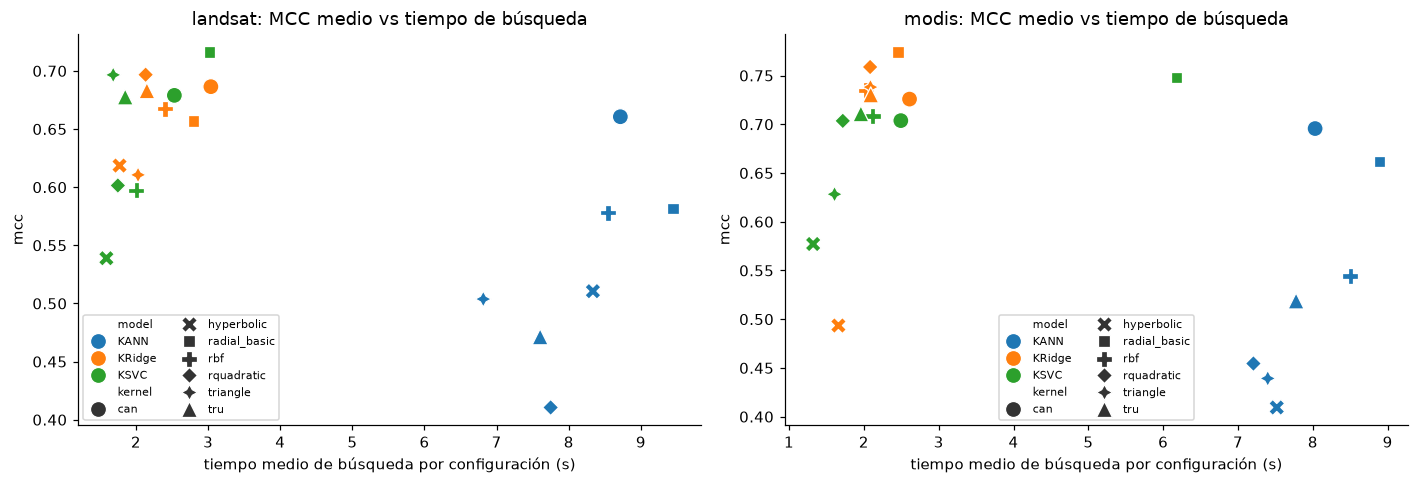

In [15]:
# Compromiso exactitud / tiempo de cómputo por kernel y modelo
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, ds in zip(ax, DATASETS):
    g = ok[ok.dataset == ds].groupby(["model", "kernel"]).agg(mcc=("mcc", "mean"), t=("fit_time_s", "mean")).reset_index()
    sns.scatterplot(data=g, x="t", y="mcc", hue="model", style="kernel", s=110, ax=a)
    a.set(title=f"{ds}: MCC medio vs tiempo de búsqueda", xlabel="tiempo medio de búsqueda por configuración (s)")
    a.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 6. Finalistas, matrices de confusión y curva Precision–Recall

**Finalistas** (por dataset, criterio `cv_f1`): los 3 mejores pipelines globales + el mejor de cada familia de modelo
(`KSVC`, `KANN`, `KRidge`), sin duplicados (se descartan los que solo difieren en el escalador). Son los que se desplegarán en la app. Se reajustan con sus mejores
hiperparámetros (sobre el mismo train) para obtener los modelos y poder dibujar sus curvas.

In [16]:
def pick_finalists(df, ds, top=3):
    # se descartan duplicados que solo difieren en el escalador (Standard y MinMax suelen empatar exactamente)
    sub = df[df.dataset == ds].sort_values("cv_f1", ascending=False).drop_duplicates(["discretizer", "reducer", "model", "kernel"])
    idx = list(sub.head(top).index) + list(sub.loc[sub.groupby("model")["cv_f1"].idxmax()].index)
    return list(dict.fromkeys(idx))

def refit(row):
    # reconstruye el pipeline ganador: discretizador + pipeline con los hiperparámetros elegidos
    ds = row["dataset"]; d = data[ds]; idx_tr, idx_te = SPLITS[ds]
    X, y = d[BANDS].values, d["value"].values
    disc = TargetDiscretizer(row["discretizer"], 3, random_state=0).fit(y[idx_tr])
    pipe = build_pipeline(row["scaler"], row["reducer"], row["model"])
    p = {("reducer__" + k[4:] if k.startswith("red_") else "model__" + k): v for k, v in row["params"].items()}
    if "model__hidden_layer_sizes" in p: p["model__hidden_layer_sizes"] = tuple(p["model__hidden_layer_sizes"])
    pipe.set_params(**p).fit(X[idx_tr], disc.transform(y[idx_tr]))
    return pipe, disc

FINAL = {}
for ds in DATASETS:
    for i in pick_finalists(ok, ds):
        row = ok.loc[i]; pipe, disc = refit(row)
        _, idx_te = SPLITS[ds]
        m = evaluate_classifier(pipe, data[ds][BANDS].values[idx_te], disc.transform(data[ds]["value"].values[idx_te]), list(disc.classes_))
        assert abs(m["mcc"] - row["mcc"]) < 1e-9, "el reajuste no reproduce la métrica guardada"
        FINAL[f"{ds}|{row['pipeline']}"] = dict(row=row, pipe=pipe, disc=disc, metrics=m)
print(len(FINAL), "finalistas (el reajuste reproduce las métricas de la búsqueda):")
pd.DataFrame([{"dataset": v["row"]["dataset"], "pipeline": v["row"]["pipeline"], "cv_f1": v["row"]["cv_f1"], **{k: v["metrics"][k] for k in METRICS}} for v in FINAL.values()]).round(3)

9 finalistas (el reajuste reproduce las métricas de la búsqueda):


,dataset,pipeline,cv_f1,accuracy,f1_macro,auc_ovr,mcc
0,landsat,MinMax | dbscan | PCA | KSVC-radial_basic,0.840,0.862,0.768,0.860,0.750
1,landsat,MinMax | hierarchical | PCA | KSVC-radial_basic,0.808,0.851,0.782,0.870,0.739
2,landsat,Normalizer | kmeans | LDA | KSVC-rquadratic,0.808,0.816,0.683,0.857,0.669
3,landsat,MinMax | hierarchical | LDA | KANN-radial_basic,0.767,0.839,0.757,0.949,0.714
4,landsat,Standard | kmeans | LDA | KRidge-can,0.805,0.805,0.602,0.912,0.646
5,modis,Standard | uniform | LDA | KSVC-rquadratic,0.845,0.854,0.726,0.858,0.741
6,modis,MinMax | uniform | LDA | KSVC-rbf,0.843,0.854,0.726,0.919,0.741
7,modis,MinMax | uniform | LDA | KRidge-rbf,0.841,0.843,0.694,0.909,0.722
8,modis,Normalizer | hierarchical | LDA | KANN-can,0.800,0.775,0.666,0.923,0.603


### 6.1 Matrices de confusión
Filas = clase real, columnas = clase predicha (conjunto de prueba, conteos).

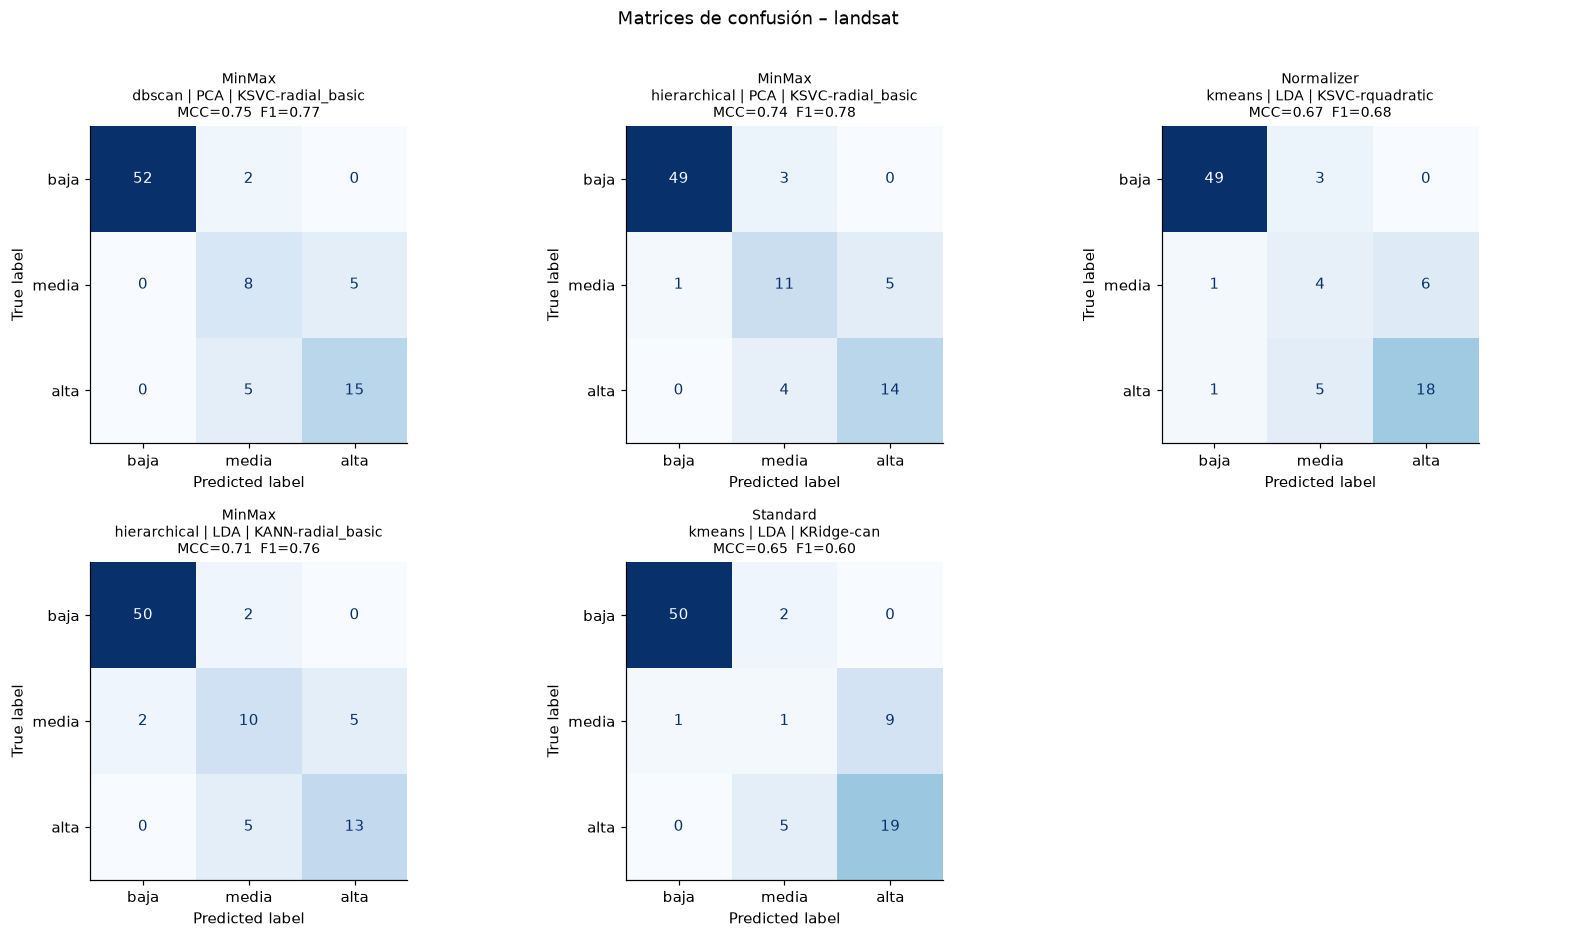

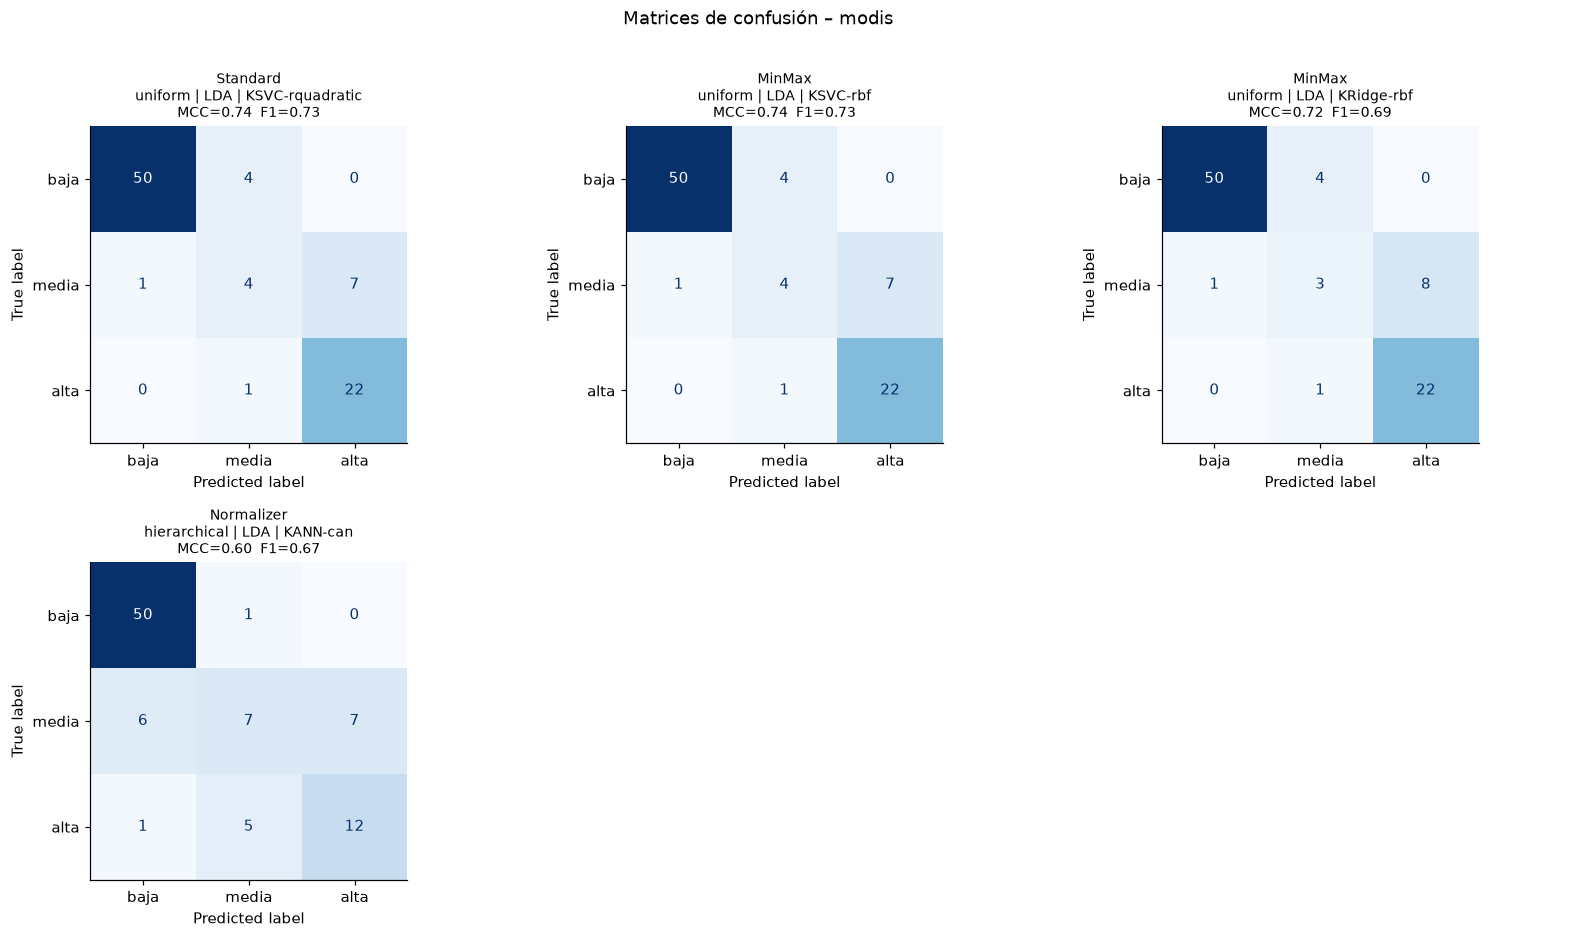

In [17]:
for ds in DATASETS:
    items = [(k, v) for k, v in FINAL.items() if k.startswith(ds + "|")]
    n = len(items); cols_ = 3; rows_ = int(np.ceil(n / cols_))
    fig, axes = plt.subplots(rows_, cols_, figsize=(5 * cols_, 4.2 * rows_)); axes = np.atleast_1d(axes).ravel()
    for a, (k, v) in zip(axes, items):
        cm = np.array(v["metrics"]["confusion_matrix"])
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=a, cmap="Blues", colorbar=False)
        a.set_title(k.split("|", 1)[1].replace(" | ", "\n", 1) + f"\nMCC={v['metrics']['mcc']:.2f}  F1={v['metrics']['f1_macro']:.2f}", fontsize=9)
    for a in axes[n:]: a.axis("off")
    fig.suptitle(f"Matrices de confusión – {ds}", y=1.01); plt.tight_layout(); plt.show()

### 6.2 ¿Curva ROC o Precision–Recall? → **Precision–Recall**
Las clases están **desbalanceadas** (la clase "baja" es ~60 % y las demás ~13–25 %, ver §3.1). La curva ROC usa la tasa de
falsos positivos, que se mantiene baja artificialmente cuando hay muchísimos negativos, por lo que **tiende a ser
optimista**. La curva **Precision–Recall** ignora los verdaderos negativos y expone directamente cuán bien se recuperan
las clases minoritarias (media y alta), que son las que interesan para identificar zonas de irradiancia. Por eso se opta
por **PR (uno-contra-todos por clase)** con su *average precision* (AP); la AUC-ROC se reporta igualmente como métrica
numérica en las tablas.

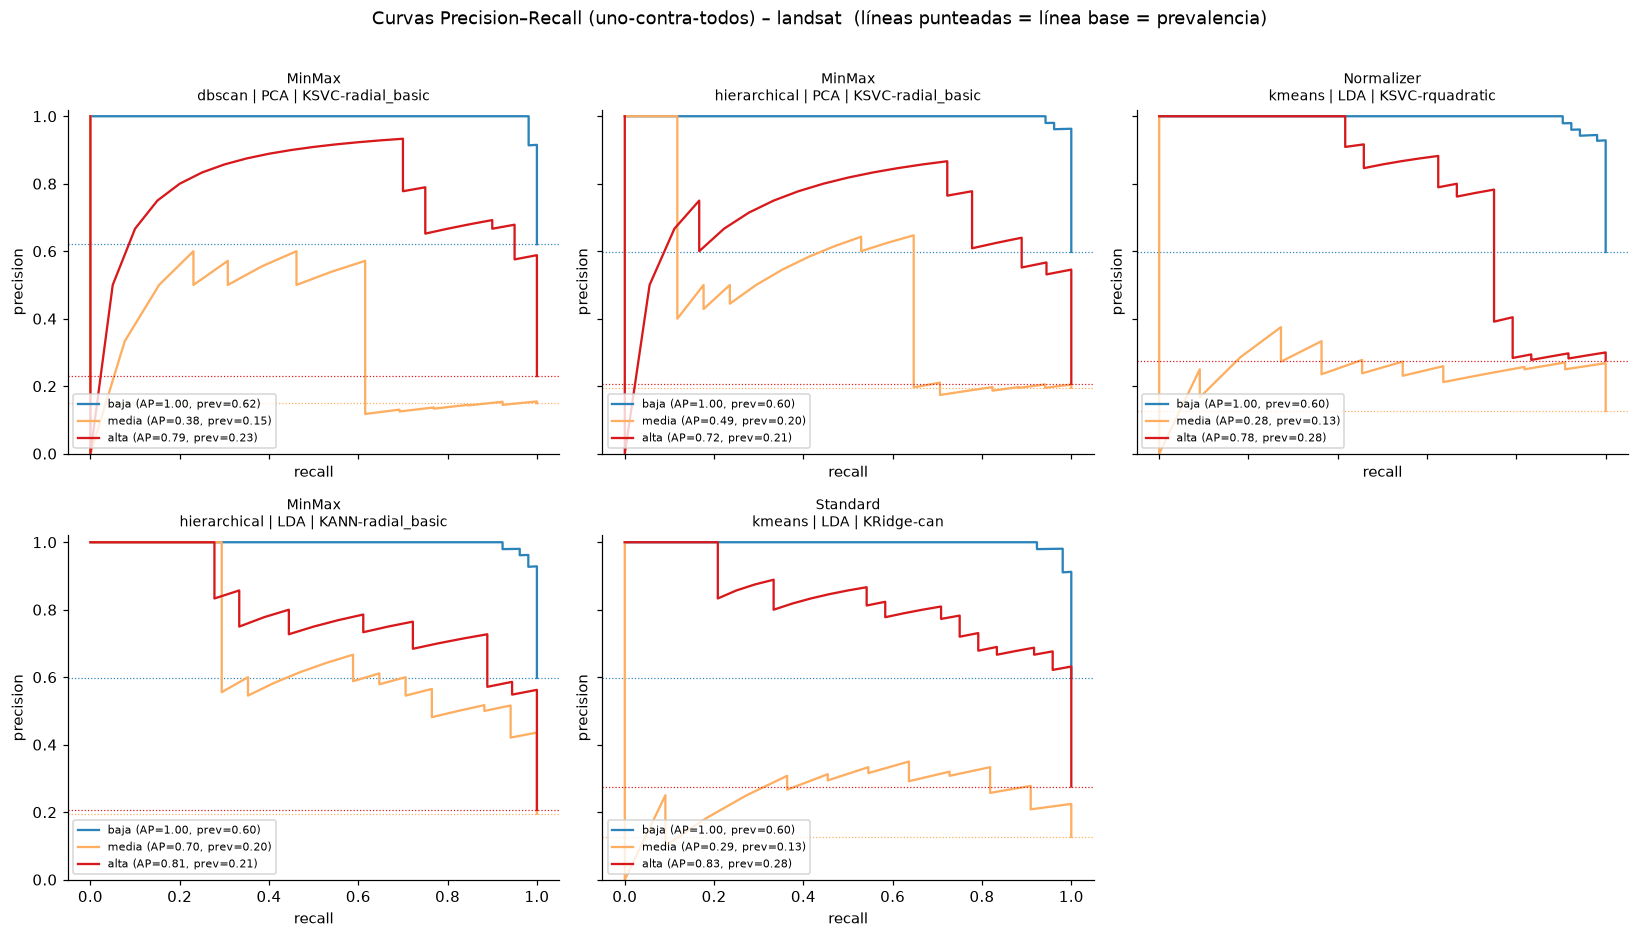

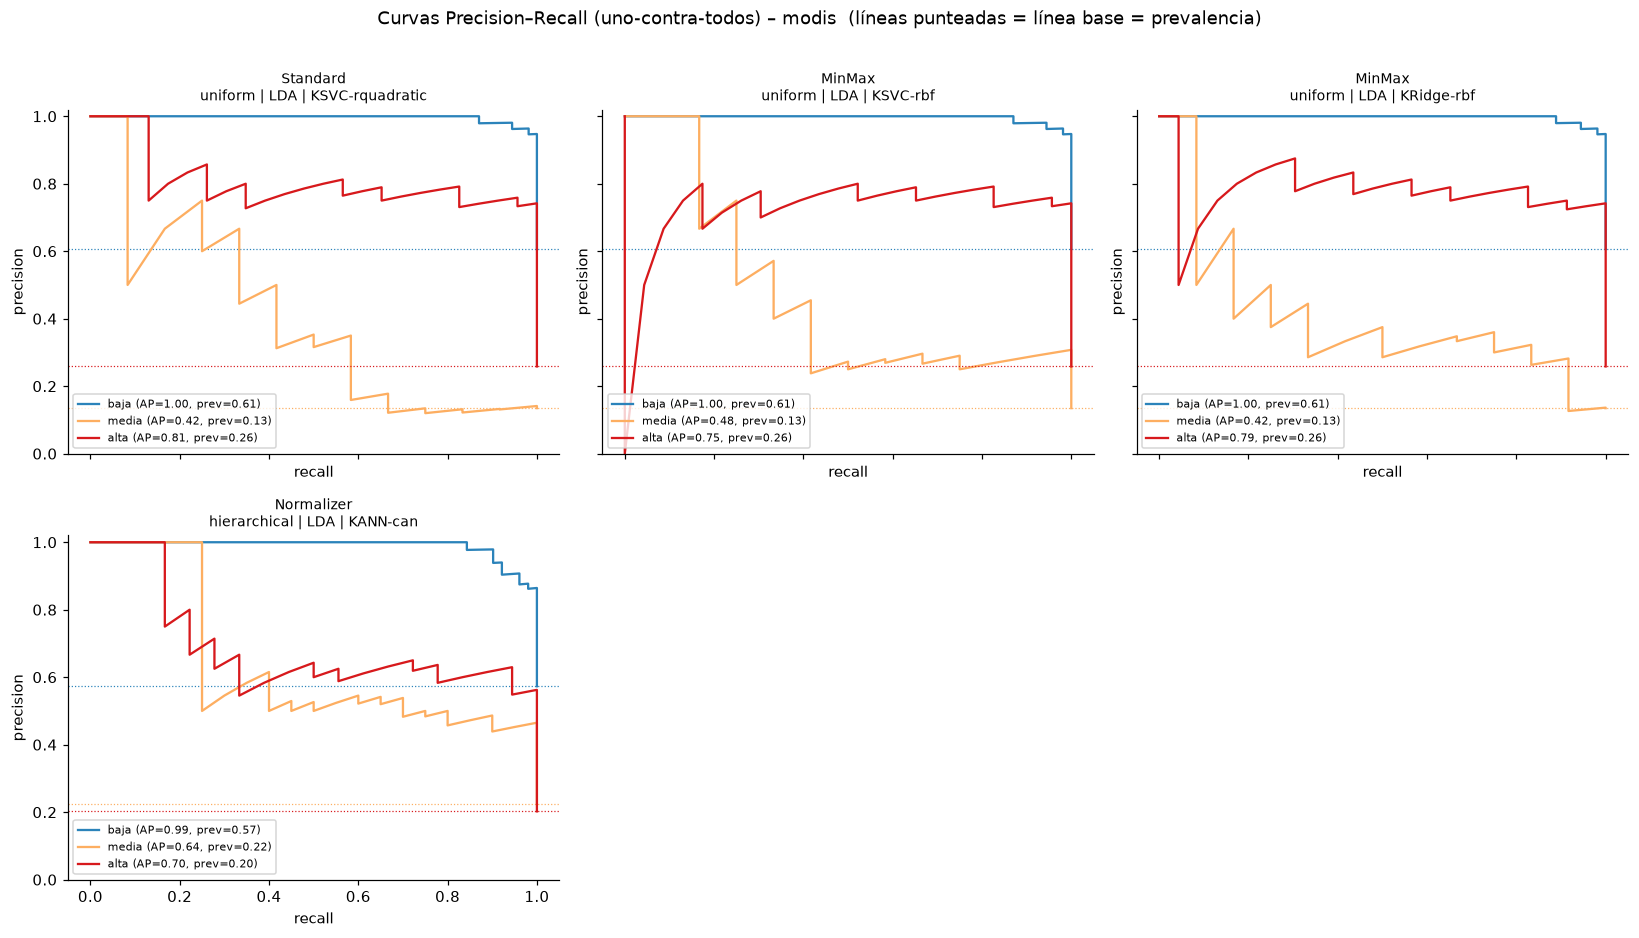

In [18]:
for ds in DATASETS:
    items = [(k, v) for k, v in FINAL.items() if k.startswith(ds + "|")]
    n = len(items); cols_ = 3; rows_ = int(np.ceil(n / cols_))
    fig, axes = plt.subplots(rows_, cols_, figsize=(5 * cols_, 4.2 * rows_), sharex=True, sharey=True); axes = np.atleast_1d(axes).ravel()
    _, idx_te = SPLITS[ds]
    for a, (k, v) in zip(axes, items):
        Xte = data[ds][BANDS].values[idx_te]; yte = v["disc"].transform(data[ds]["value"].values[idx_te])
        S = class_scores(v["pipe"], Xte); Y = label_binarize(yte, classes=list(v["disc"].classes_))
        for c in range(Y.shape[1]):
            p, r, _ = precision_recall_curve(Y[:, c], S[:, c])
            a.plot(r, p, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (AP={average_precision_score(Y[:, c], S[:, c]):.2f}, prev={Y[:, c].mean():.2f})")
            a.axhline(Y[:, c].mean(), color=CLASS_COLORS[c], ls=":", lw=.8)
        a.set(xlabel="recall", ylabel="precision", ylim=(0, 1.02)); a.legend(fontsize=7, loc="lower left")
        a.set_title(k.split("|", 1)[1].replace(" | ", "\n", 1), fontsize=9)
    for a in axes[n:]: a.axis("off")
    fig.suptitle(f"Curvas Precision–Recall (uno-contra-todos) – {ds}  (líneas punteadas = línea base = prevalencia)", y=1.01)
    plt.tight_layout(); plt.show()

### 6.3 Variabilidad de los finalistas (evaluación repetida)
Como el test tiene pocas filas, se repite el *hold-out* estratificado 10 veces (semillas distintas) con los hiperparámetros
**fijos** de cada finalista. No sustituye al protocolo principal; sirve para ver cuánto varían las métricas.

In [19]:
from sklearn.model_selection import StratifiedShuffleSplit
rows_ = []
for k, v in FINAL.items():
    ds = v["row"]["dataset"]; d = data[ds]; X, y = d[BANDS].values, d["value"].values
    strat = pd.qcut(d["value"], 5, labels=False, duplicates="drop")
    mm = {m: [] for m in METRICS}
    for tr_i, te_i in StratifiedShuffleSplit(10, test_size=0.2, random_state=SEED).split(X, strat):
        disc = TargetDiscretizer(v["row"]["discretizer"], 3, random_state=0).fit(y[tr_i])
        pipe = clone(v["pipe"]).fit(X[tr_i], disc.transform(y[tr_i]))
        m = evaluate_classifier(pipe, X[te_i], disc.transform(y[te_i]), list(disc.classes_))
        for q in METRICS: mm[q].append(m[q])
    rows_.append({"dataset": ds, "pipeline": v["row"]["pipeline"], **{f"{q}": f"{np.mean(mm[q]):.3f} ± {np.std(mm[q]):.3f}" for q in METRICS}})
REPEATED = pd.DataFrame(rows_); REPEATED

,dataset,pipeline,accuracy,f1_macro,auc_ovr,mcc
0,landsat,MinMax | dbscan | PCA | KSVC-radial_basic,0.892 ± 0.037,0.743 ± 0.057,0.872 ± 0.049,0.798 ± 0.066
1,landsat,MinMax | hierarchical | PCA | KSVC-radial_basic,0.883 ± 0.029,0.807 ± 0.031,0.887 ± 0.023,0.793 ± 0.050
2,landsat,Normalizer | kmeans | LDA | KSVC-rquadratic,0.856 ± 0.025,0.709 ± 0.040,0.895 ± 0.023,0.741 ± 0.046
3,landsat,MinMax | hierarchical | LDA | KANN-radial_basic,0.837 ± 0.041,0.667 ± 0.082,0.927 ± 0.029,0.709 ± 0.075
4,landsat,Standard | kmeans | LDA | KRidge-can,0.871 ± 0.034,0.744 ± 0.075,0.923 ± 0.030,0.764 ± 0.061
5,modis,Standard | uniform | LDA | KSVC-rquadratic,0.889 ± 0.038,0.778 ± 0.086,0.900 ± 0.045,0.801 ± 0.070
6,modis,MinMax | uniform | LDA | KSVC-rbf,0.891 ± 0.033,0.783 ± 0.073,0.924 ± 0.025,0.805 ± 0.060
7,modis,MinMax | uniform | LDA | KRidge-rbf,0.884 ± 0.038,0.764 ± 0.085,0.955 ± 0.024,0.793 ± 0.069
8,modis,Normalizer | hierarchical | LDA | KANN-can,0.871 ± 0.063,0.711 ± 0.091,0.930 ± 0.031,0.767 ± 0.112


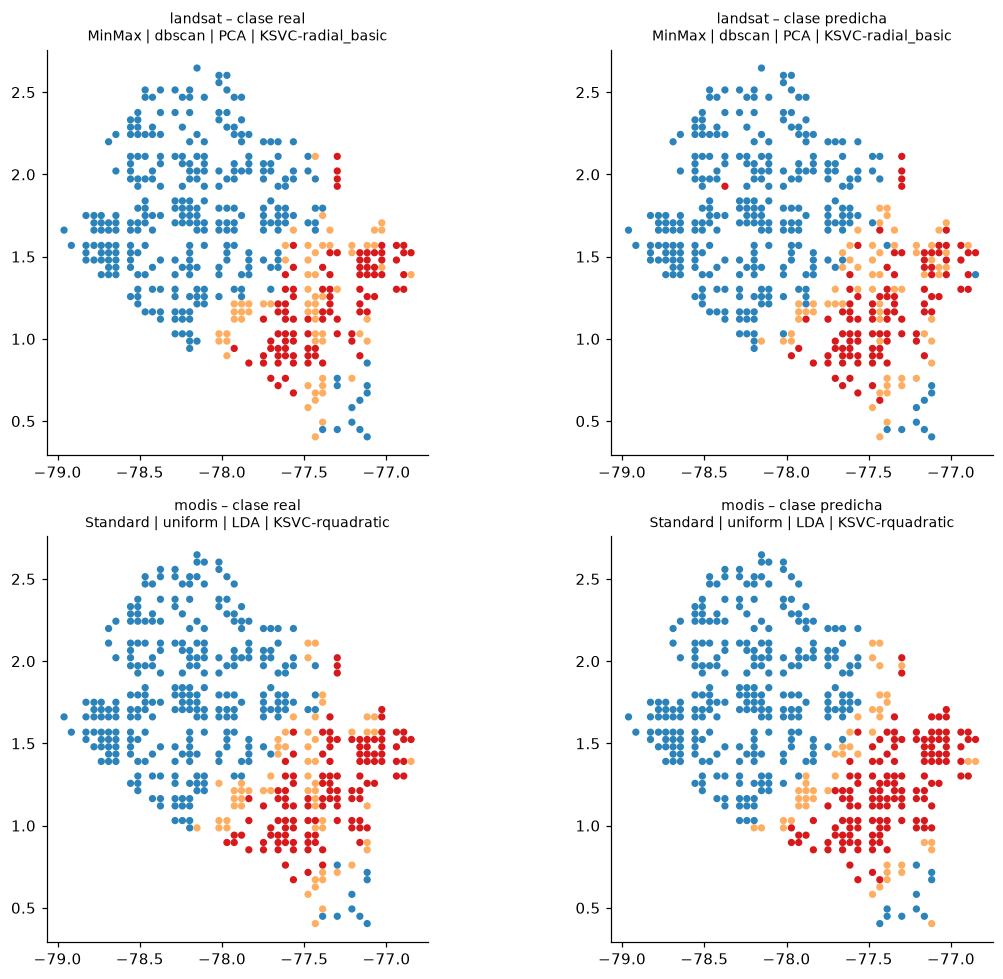

In [20]:
# Mapa de los finalistas (coordenadas EPSG:3857): clase real vs predicha por el mejor pipeline de cada dataset (todos los píxeles)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, ds in enumerate(DATASETS):
    k, v = max(((k, v) for k, v in FINAL.items() if k.startswith(ds + "|")), key=lambda kv: kv[1]["row"]["cv_f1"])
    d = data[ds]; real = v["disc"].transform(d["value"].values); pred = v["pipe"].predict(d[BANDS].values)
    for a, lab, t in [(axes[r, 0], real, "clase real"), (axes[r, 1], pred, "clase predicha")]:
        a.scatter(d["lon_deg"], d["lat_deg"], c=[CLASS_COLORS[i] for i in lab], s=14)
        a.set_title(f"{ds} – {t}\n{v['row']['pipeline']}", fontsize=9); a.set_aspect("equal")
plt.tight_layout(); plt.show()

## 7. Conclusiones

In [21]:
for ds in DATASETS:
    b = ok[ok.dataset == ds].sort_values("cv_f1", ascending=False).iloc[0]
    print(f"[{ds}] mejor pipeline por CV: {b['pipeline']} | cv_f1={b['cv_f1']:.3f} | test: acc={b['accuracy']:.3f} f1={b['f1_macro']:.3f} auc={b['auc_ovr']:.3f} mcc={b['mcc']:.3f}")
    print("   params:", b["params"])
    print("   kernel (MCC medio test):", ok[ok.dataset == ds].groupby("kernel")["mcc"].mean().sort_values(ascending=False).round(3).to_dict())
    print("   modelo (MCC medio test):", ok[ok.dataset == ds].groupby("model")["mcc"].mean().sort_values(ascending=False).round(3).to_dict())
    print("   escalador (MCC medio):", ok[ok.dataset == ds].groupby("scaler")["mcc"].mean().sort_values(ascending=False).round(3).to_dict())
    print("   reductor (MCC medio):", ok[ok.dataset == ds].groupby("reducer")["mcc"].mean().sort_values(ascending=False).round(3).to_dict())

[landsat] mejor pipeline por CV: MinMax | dbscan | PCA | KSVC-radial_basic | cv_f1=0.840 | test: acc=0.862 f1=0.768 auc=0.860 mcc=0.750
   params: {'C': 2.075496247003056, 'degree': 4, 'gamma': 0.13367246313467795, 'kernel': 'radial_basic', 'red_n_components': 5}
   kernel (MCC medio test): {'can': 0.675, 'radial_basic': 0.652, 'rbf': 0.614, 'tru': 0.611, 'triangle': 0.604, 'rquadratic': 0.57, 'hyperbolic': 0.556}
   modelo (MCC medio test): {'KRidge': 0.66, 'KSVC': 0.644, 'KANN': 0.531}
   escalador (MCC medio): {'MinMaxScaler': 0.674, 'StandardScaler': 0.643, 'Normalizer': 0.519}
   reductor (MCC medio): {'LDA': 0.705, 'PCA': 0.518}
[modis] mejor pipeline por CV: Standard | uniform | LDA | KSVC-rquadratic | cv_f1=0.845 | test: acc=0.854 f1=0.726 auc=0.858 mcc=0.741
   params: {'C': 113.38919272254311, 'coef0': 300.72140967174505, 'kernel': 'rquadratic'}
   kernel (MCC medio test): {'radial_basic': 0.728, 'can': 0.708, 'rbf': 0.663, 'tru': 0.653, 'rquadratic': 0.639, 'triangle': 0.602

**Resultados principales** (1008 configuraciones; selección por F1-macro de validación cruzada; métricas en test):

| Dataset | Mejor pipeline (CV) | Accuracy | F1-macro | AUC | MCC |
|---|---|---|---|---|---|
| Landsat | MinMax · DBSCAN · PCA · **KSVC** (`radial_basic`) | 0.862 | 0.768 | 0.860 | 0.750 |
| MODIS | Standard · uniform · LDA · **KSVC** (`rquadratic`) | 0.854 | 0.726 | 0.858 | 0.741 |

1. **Kernels.** En ambos datasets los kernels de mejor desempeño medio fueron `radial_basic` (ANOVA) y `can` (Canberra),
   seguidos de `rbf`/`tru`; los mejores pipelines individuales usan `radial_basic` (Landsat) y `rquadratic` / `rbf` (MODIS).
   El kernel `hyperbolic` fue el peor en promedio: no es definido positivo en general, lo que perjudica a SVM y a Ridge.
   Esto es coherente con el artículo de referencia (que recomienda `radial_basic` / `rquadratic` / `rbf`).
2. **Modelos.** `KSVC` y `KRidgeClassifier` (el nuevo clasificador con truco kernel) rinden de forma muy parecida y
   `KRidge` es bastante más barato de entrenar; `KANN` es el más débil en promedio con este presupuesto de búsqueda
   (Nyström con 100 componentes, activación identidad, 20 candidatos) y es el más lento (hasta ~20 s por búsqueda).
   `KANN` sí alcanza los mejores AUC de los finalistas, es decir, ordena bien las clases aunque su umbral de decisión
   es menos preciso.
3. **Reductor.** `LDA` supera con claridad a `PCA` (MCC medio ≈ 0.71–0.72 vs ≈ 0.52–0.57): al ser supervisado proyecta
   justo en las direcciones que separan las clases, mientras que `PCA` solo conserva varianza. Ojo: LDA queda limitado a
   2 componentes (clases − 1) y PCA se probó con 2, 3 y 5.
4. **Escalador.** `Normalizer` (normalización por fila) es el peor en Landsat (destruye la magnitud relativa entre bandas
   de escalas muy distintas, p. ej. `band6` ≈ 295 vs las demás ≈ 0.05–0.4); en MODIS las diferencias entre escaladores
   son pequeñas. `MinMax` y `Standard` son prácticamente equivalentes.
5. **Discretizador.** `uniform`, `kmeans` y `hierarchical` generan clases casi idénticas (distribución bimodal); `DBSCAN`
   produce una clase intermedia más pequeña. Como cada discretizador define un problema distinto, sus métricas no son
   estrictamente comparables entre sí; que DBSCAN aparezca primero en Landsat debe leerse con esa cautela.
6. **Incertidumbre.** Con ~87 filas de test, la evaluación repetida (§6.3) muestra desviaciones de ≈ 0.03–0.09 en las
   métricas (MCC ≈ 0.79–0.80 ± 0.06 en los mejores). Las diferencias entre los primeros pipelines (≈ 0.01–0.04) **están
   dentro de ese ruido**: no hay evidencia para afirmar que uno sea realmente mejor que otro entre los finalistas; sí la
   hay para afirmar que LDA > PCA, que `hyperbolic` y `Normalizer` (en Landsat) son peores y que `KANN` rinde menos.
7. **Curva.** Dado el desbalance (clase baja ≈ 60 %), la curva Precision–Recall es la más informativa: muestra que la clase
   **media** es la difícil (las matrices de confusión la confunden con la alta), y que la clase baja se recupera casi
   siempre.

**Limitaciones.** Un solo split principal; búsqueda aleatoria reducida (20 candidatos); `uniform` se interpretó como
rangos de igual ancho (`KBinsDiscretizer(strategy="uniform")`), no como cuantiles.

## 8. Exportación de los mejores pipelines para la aplicación web (punto 5a)

Cada finalista se guarda con `kernelml.registry.save_model_bundle` en `webapp/seed_models/` como `<id>.joblib` (pipeline
entrenado + discretizador + metadatos) y `<id>.json`
(metadatos: dataset, hiperparámetros, métricas, matriz de confusión, rangos de irradiancia por clase). La app web
(`webapp/app.py`) carga estos archivos al iniciar y permite además **subir/almacenar** nuevos modelos con el mismo formato.
También se copian los CSV a `webapp/data/`.

In [22]:
from kernelml.registry import save_model_bundle, slugify
import shutil
OUT = "webapp/seed_models"; os.makedirs("webapp/data", exist_ok=True)
for f in DATASETS.values(): shutil.copy(f, "webapp/data/" + f)
if os.path.isdir(OUT):
    for old in os.listdir(OUT): os.remove(os.path.join(OUT, old))
index = []
for key, v in FINAL.items():
    row, ds = v["row"], v["row"]["dataset"]
    meta = dict(id=f"{ds}-{row['pipeline']}", name=f"{ds} · {row['pipeline']}", dataset=ds, scaler=row["scaler"],
                discretizer=row["discretizer"], reducer=row["reducer"], model=row["model"], kernel=row["kernel"],
                params=row["params"], features=BANDS, cv_f1=float(row["cv_f1"]),
                metrics={k: float(v["metrics"][k]) for k in METRICS}, confusion_matrix=v["metrics"]["confusion_matrix"],
                class_names=CLASS_NAMES[:v["disc"].n_classes_], class_ranges=v["disc"].ranges_,
                class_counts_train=v["disc"].counts_)
    index.append(save_model_bundle(v["pipe"], v["disc"], meta, OUT))
print(len(index), "modelos exportados a", OUT); print(", ".join(index))

9 modelos exportados a webapp/seed_models
landsat-minmax-dbscan-pca-ksvc-radial-basic, landsat-minmax-hierarchical-pca-ksvc-radial-basic, landsat-normalizer-kmeans-lda-ksvc-rquadratic, landsat-minmax-hierarchical-lda-kann-radial-basic, landsat-standard-kmeans-lda-kridge-can, modis-standard-uniform-lda-ksvc-rquadratic, modis-minmax-uniform-lda-ksvc-rbf, modis-minmax-uniform-lda-kridge-rbf, modis-normalizer-hierarchical-lda-kann-can
